### Case Study: **Adamello Batholith, Italy**

*Primitive to Evolved - Subalkaline Calcalkaline*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/italy/adamello.ipynb)

The Adamello Batholith is located in Italy and features calc-alkaline, island arc rocks with primitive dyke compositions. Hades replicates an experimental fractional crystallisation study by Nandedkar (2014), which used a synthetic version of the Adamello primitive dykes as a starting composition to experimentally reconstruct the fractional sequence. Hades uses the mineralogy present in each step of these experiments to replicate the fractionation sequence produced.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/italy/adamello) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/italy/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [1]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel(
    submode='calcalkaline',    
)

# Load the data suite
model.load_data_suite('./adamello.xlsx')

# Use Hades' default selection of the projected LLOD [automatically calculated]

hades-obol v0.8.4. This is a pre-release version. Check for updates using hades.check_for_updates()


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

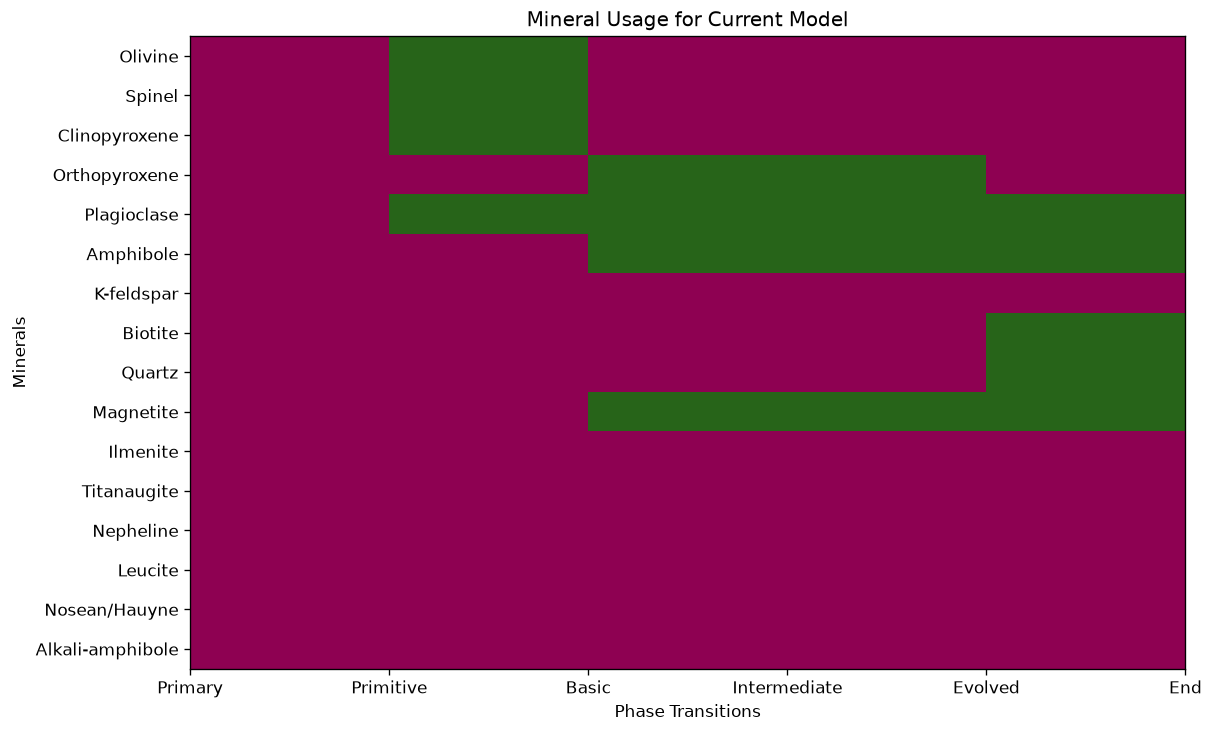

In [2]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    primary__=False,
    primitive__ilmenite=False,
    primitive__amphibole=False,
    primitive__magnetite=False,
    basic__=False,
    intermediate__=False,
    evolved__=False,
    basic__amphibole=True,
    basic__plagioclase=True,
    basic__opx=True,
    basic__magnetite=True,
    intermediate__amphibole=True,
    intermediate__plagioclase=True,
    intermediate__opx=True,
    intermediate__magnetite=True,
    evolved__amphibole=True,
    evolved__plagioclase=True,
    evolved__magnetite=True,
    evolved__biotite=True,
    evolved__quartz=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [3]:
# Specify the mineralogical compositions for minerals and phases (in wt.%)
model.set_mineralogies(
    primitive__olivine =        [38.67, 0.02, 0.03, 17.48, 43.5, 0.27, 0.01, 0.01],
    primitive__cpx =            [51.69, 0.38, 3.97, 5.69, 16.3, 21.72, 0.24, 0.01],
    basic__opx =                [49.34, 0.37, 6.38, 17.8, 24.43, 1.64, 0.03, 0.02],
    basic__amphibole =          [40.91, 1.76, 15.53, 14.03, 13.92, 11.03, 2.34, 0.48],
    basic__plagioclase =               [46.68, 0.02, 33.35, 0.74, 0.06, 17.37, 1.71, 0.06],
    basic__mag =                [0.07, 4.72, 13.92, 76.87, 4.23, 0.15, 0.03, 0.02],
    intermediate__amphibole =   [43.62, 2.01, 13.26, 11.58, 15.8, 11.14, 2.19, 0.41],
    intermediate__plagioclase =        [47.78, 0.06, 32.59, 1.06, 0.33, 16.18, 1.88, 0.12],
    intermediate__opx =         [51.78, 0.28, 5.84, 14.01, 26.66, 1.27, 0.09, 0.07],
    intermediate__mag =         [0.13, 12.93, 0.89, 84.9, 0.99, 0.08, 0.03, 0.04],
    evolved__plagioclase =             [59.3, 0.02, 28.04, 0.38, 0.15, 4.67, 6.97, 0.48],
    evolved__mag =              [0.31, 5.4, 0.42, 93.35, 0.4, 0.01, 0.03, 0.07],
    evolved__qz =              [99.82, 0, 0.08, 0.04, 0, 0.03, 0, 0.02],
    evolved__biotite =          [41.37, 2.07, 17.6, 9.43, 19.77, 0.01, 0.92, 8.82],
)

Normalising composition for primitive__olivine to 100 wt%. Original sum: 99.99
Normalising composition for basic__opx to 100 wt%. Original sum: 100.01
Normalising composition for basic__plagioclase to 100 wt%. Original sum: 99.99
Normalising composition for basic__mag to 100 wt%. Original sum: 100.01
Normalising composition for intermediate__amphibole to 100 wt%. Original sum: 100.01
Normalising composition for intermediate__mag to 100 wt%. Original sum: 99.99
Normalising composition for evolved__plagioclase to 100 wt%. Original sum: 100.01
Normalising composition for evolved__mag to 100 wt%. Original sum: 99.99
Normalising composition for evolved__qz to 100 wt%. Original sum: 99.99
Normalising composition for evolved__biotite to 100 wt%. Original sum: 99.99


In [4]:
# Set experimental or literature-based KD values for the minerals and phases 
model.set_KDs(
    __plagioclase=3.2, 
)

**Optimisation**

In [5]:
# Run stages 2 through 5 (primitive-basic through evolved-end)
model.run(2)
model.run(3)
model.run(4)
model.run(5)

> Optimisation completed with cost = 0.32 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.35 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.56 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 2.29 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [6]:
model.summary()

                        P-B        B-I        I-E        E-e     |     Total   
------------------------------------------------------------------------------------------------
            Type  |    Majors     Majors     Majors     Majors   |            
            Cost  |      0.32       0.35       0.56       2.29   |            
------------------------------------------------------------------------------------------------
               F  |        32         34         41         25   |       100    %
         Olivine  |     9.007                                    |     3.596    wt.%
          Spinel  |    11.805                                    |     4.714    wt.%
   Clinopyroxene  |    70.813                                    |    28.276    wt.%
   Orthopyroxene  |                3.624      6.984              |     2.649    wt.%
     Plagioclase  |     8.374     32.291     68.458     66.574   |    33.877    wt.%
       Amphibole  |               49.653     17.639     18.25

**Visualising Results**

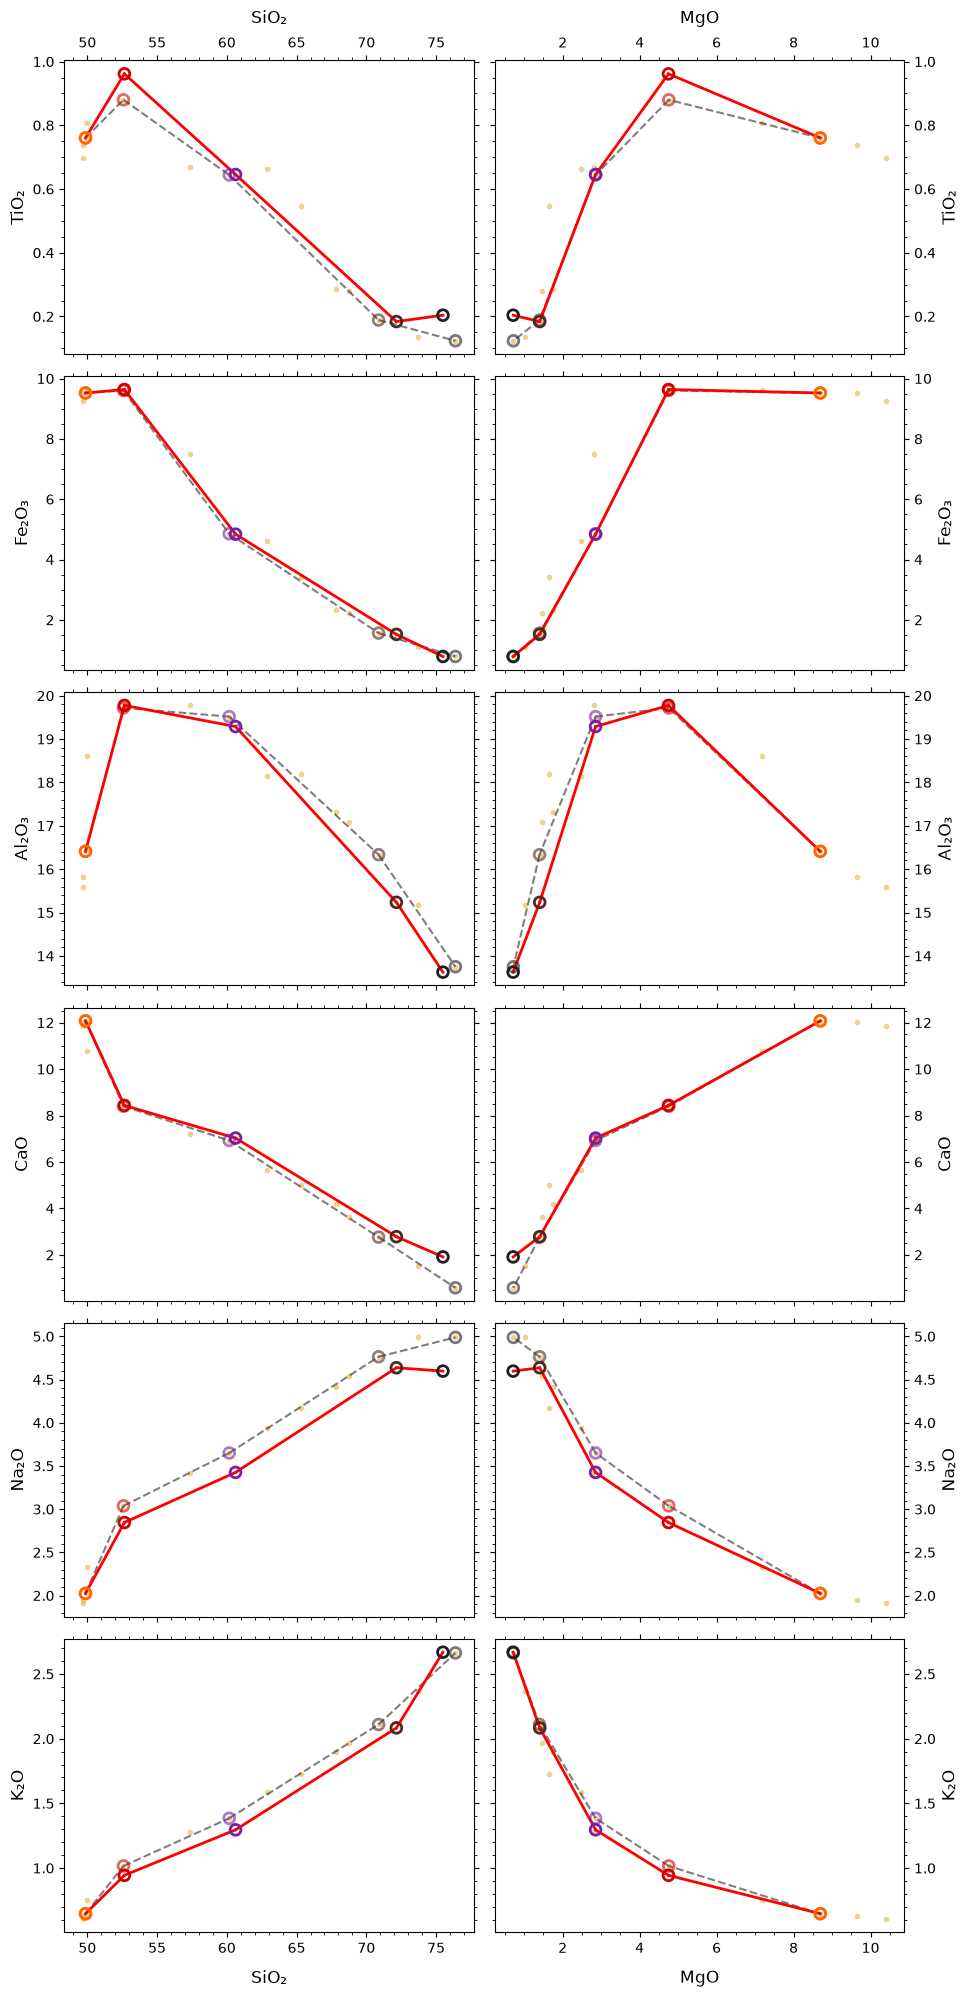

In [7]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

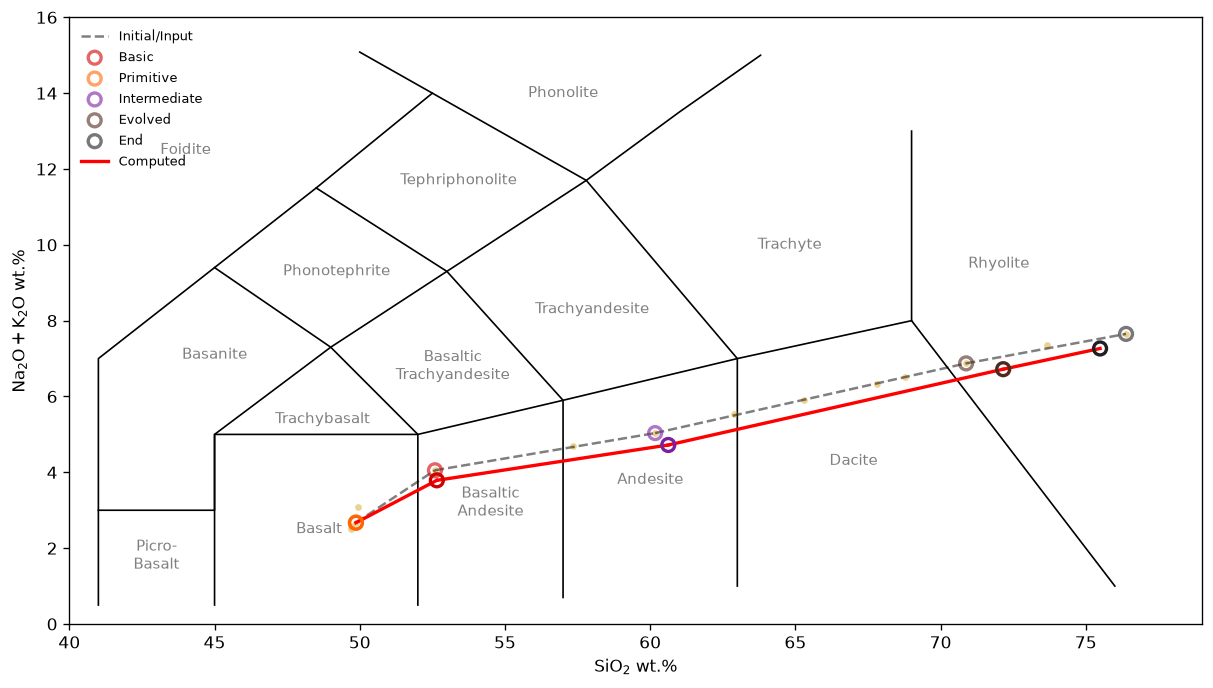

In [8]:
# Plot the TAS diagram and save to a file
from hades.visuals import tas
tas(
    model, 
    filename='./outputs/tas_diagram.png'
)

**Trace Element Modelling**

To model trace elements, we perturb the optimal solution found above with your chosen wt.%s of accessory minerals. Hades re-models fractional crystallisation with the new bulk composition and outputs the trace element results.

We can use trial-and-error to find the best-fitting accessory mineral proportions, utilising the ``harker()`` function to visualise the results.

In [9]:
# For each stage, we provide the wt.% of apatite, zircon, monazite and allanite

# No accessory minerals in the primitive stage (does not need to be run)
# model.runTraces(2, [0, 0, 0, 0])
# 0.1 wt.% apatite in the basic-intermediate stage
model.runTraces(3, [0.1, 0, 0, 0])
# 0.7 wt.% apatite in the intermediate-evolved stage
model.runTraces(4, [0.7, 0, 0, 0])
# 1 wt.% apatite in the evolved-end stage
model.runTraces(5, [1, 0, 0, 0])

Trace element analyses were run. Using trace results for mineral proportions.
Trace element analyses were run. Using trace results for mineral proportions.
Trace element analyses were run. Using trace results for mineral proportions.


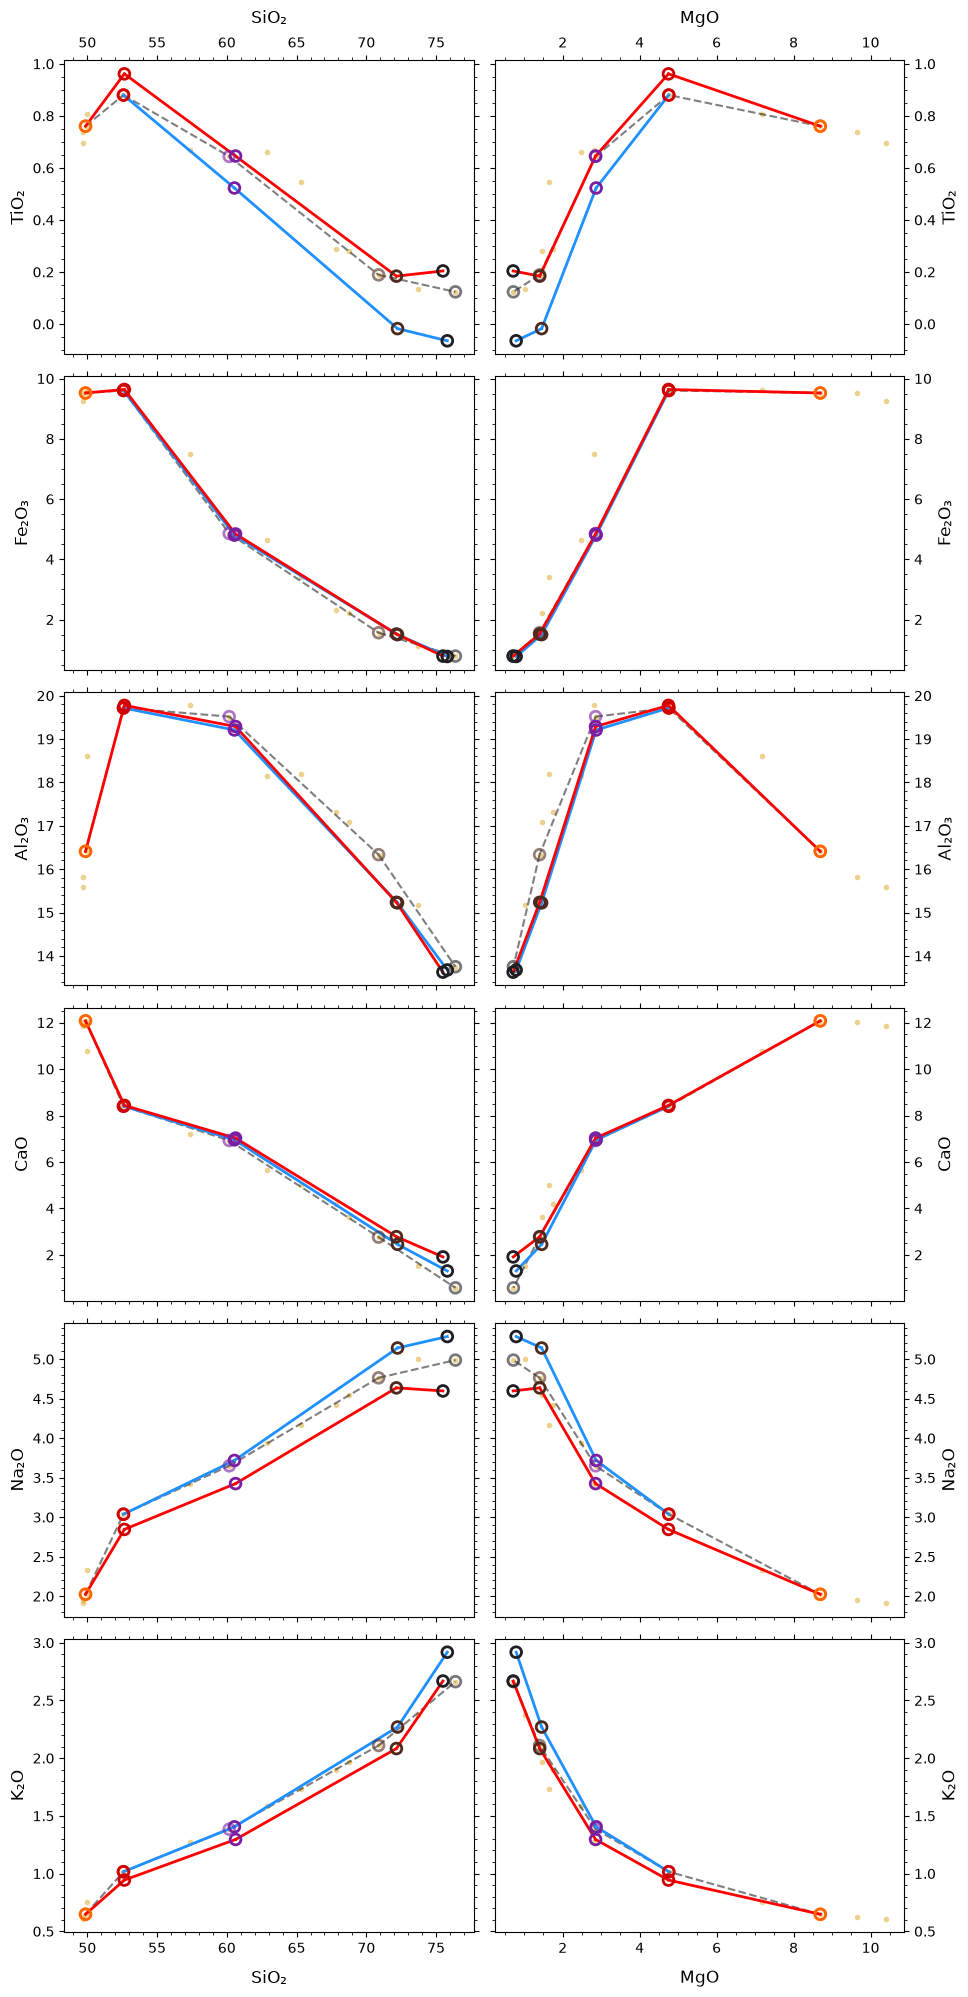

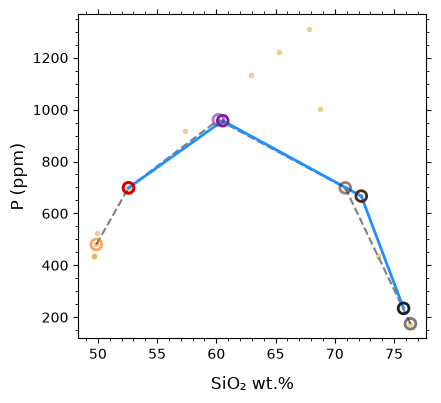

In [10]:
bivar(
    model, 
    mode='traces',
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots_trace_elements.png',
)

from hades.visuals import harker
harker(
    model, 
    y_order=['P'], 
    filename="./outputs/harker_plots.png"
)

**Export Results**

Note that we can export results prior to or without trace element modelling, which will omit such results from the output files.

In [11]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [12]:
model.save_config('./adamello.hades')

Successfully saved configuration to ./adamello.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [13]:
model = Obol.newModel()
model.load_config('./adamello.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [14]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default

**References**

Rohit H Nandedkar. Evolution of hydrous mantle-derived calc-alkaline liquids by fractional crystallization at 0.7 and 0.4 GPa: An experimental study. PhD thesis, ETH Zurich, 2014.